# Predicció del dia següent amb FPCA / MFPCA + VAR: eòlica i preu (ESIOS)

Autor: Leonel Fernando Nabaza Ruibal

Pipeline de predicció de sèries temporals funcionals, seguint la idea d'Aue, Dubart Norinho
i Hörmann (2015), *On the prediction of stationary functional time series* (JASA):

$$
\underbrace{\text{dades històriques}}_{\text{ESIOS}}
\;\longrightarrow\;
\underbrace{x_i(t)}_{\text{dades funcionals}}
\;\longrightarrow\;
\underbrace{\boldsymbol{\xi}_i}_{\text{FPCA / MFPCA}}
\;\longrightarrow\;
\underbrace{\hat{\boldsymbol{\xi}}_{n+1}}_{\text{VAR}}
\;\longrightarrow\;
\underbrace{\hat{x}_{n+1}(t)}_{\text{reconstrucció}}
$$

La idea: en comptes de predir directament 288 + 96 valors per dia, es redueix cada dia a
uns pocs scores de components principals, es prediuen aquests scores amb un model VAR i
es reconstrueix la corba a partir dels scores predits.

Es comparen dues opcions per a la reducció de dimensió:

- **A. FPCA per separat**: una FPCA per a l'eòlica i una altra per al preu.
- **B. MFPCA** (Happ & Greven, 2018): components conjuntes de les dues variables.


In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.tsa.api import VAR
from statsmodels.tsa.stattools import adfuller

from FDApy.preprocessing.dim_reduction.mfpca import MFPCA
from FDApy.preprocessing.dim_reduction.ufpca import UFPCA
from FDApy.representation.argvals import DenseArgvals
from FDApy.representation.functional_data import DenseFunctionalData, MultivariateFunctionalData
from FDApy.representation.values import DenseValues

warnings.filterwarnings("ignore")

CARPETA = "dades_esios"
ZONA = "Europe/Madrid"
VAR_EXPLICADA = 0.95   # proporció de variància que han de retenir les components
MAX_LAGS = 7           # ordre màxim del VAR que es prova
N_TEST = 60            # dies de l'avaluació rodant


---
# Part 1 — Dades històriques: dies consecutius

Per a un model de sèries temporals els dies han de ser **consecutius**: si n'eliminem un,
el VAR tractaria com a "dia anterior" un dia que no ho és. Per això, en lloc de fer servir
les matrius de corbes (que excloïen els canvis d'hora), reconstruïm les corbes des de les
sèries originals (`eolica_raw.csv`, `preu_raw.csv`):

- **Dia de 25 h** (octubre): l'hora repetida (02:00–02:59) s'assigna dues vegades al
  mateix minut del dia i es fa la mitjana dels dos valors.
- **Dia de 23 h** (març): l'hora que no existeix (02:00–02:59) queda buida i s'omple
  per interpolació lineal entre 01:55 i 03:00.

La **resolució** de cada sèrie (5 min, 15 min, …) no s'indica a mà: es dedueix de les
dades (diferència mediana entre instants consecutius). Així el notebook funciona igual
si es descarreguen les dades amb una altra granularitat.

El **temps es manté en hores**, $t \in [0, 24)$, sense reescalar: cada punt de la malla
és $t = \text{minuts des de les 00:00} / 60$.


In [2]:
def corbes_consecutives(fitxer, divisor=1.0):
    # Sèrie original -> (matriu dies x punts del dia amb dies consecutius, malla en hores)
    df = pd.read_csv(fitxer)
    t = pd.to_datetime(df["datetime_utc"], utc=True).dt.tz_convert(ZONA)
    # Resolució deduïda de les dades (minuts entre instants consecutius)
    resolucio = int(t.drop_duplicates().sort_values().diff().median().total_seconds() // 60)
    df = df.assign(dia=t.dt.date,
                   minut=t.dt.hour * 60 + t.dt.minute,
                   value=pd.to_numeric(df["value"], errors="coerce") / divisor)
    m = df.pivot_table(index="dia", columns="minut", values="value", aggfunc="mean")
    m = m.reindex(columns=np.arange(0, 24 * 60, resolucio))
    m.index = pd.to_datetime(m.index)
    m = m.reindex(pd.date_range(m.index.min(), m.index.max()))   # cap dia perdut
    buits = m.index[m.isna().any(axis=1)]
    print(f"{fitxer}: resolució {resolucio} min ({m.shape[1]} punts/dia), {len(m)} dies, "
          f"punts buits {int(m.isna().sum().sum())} als dies {[d.date().isoformat() for d in buits]}")
    malla_hores = m.columns.to_numpy() / 60   # t en hores: 0, 5/60, ..., sense reescalar
    return m.interpolate(axis=1, limit_direction="both"), malla_hores


E, te = corbes_consecutives(f"{CARPETA}/eolica_raw.csv", divisor=1000)   # GW
P, tp = corbes_consecutives(f"{CARPETA}/preu_raw.csv")                   # €/MWh

dies = E.index.intersection(P.index)
Xe, Xp = E.loc[dies].to_numpy(), P.loc[dies].to_numpy()
n = len(dies)
print(f"\nDies consecutius: {n} ({dies.min().date()} -> {dies.max().date()})")
print(f"Eòlica: {Xe.shape}   Preu: {Xp.shape}")
print(f"Malla eòlica: {te[:3]} ... {te[-1]:.4f} h   |   malla preu: {tp[:3]} ... {tp[-1]:.4f} h")


dades_esios/eolica_raw.csv: resolució 5 min (288 punts/dia), 396 dies, punts buits 12 als dies ['2026-03-29']


dades_esios/preu_raw.csv: resolució 15 min (96 punts/dia), 396 dies, punts buits 4 als dies ['2026-03-29']

Dies consecutius: 396 (2025-10-01 -> 2026-10-31)
Eòlica: (396, 288)   Preu: (396, 96)
Malla eòlica: [0.         0.08333333 0.16666667] ... 23.9167 h   |   malla preu: [0.   0.25 0.5 ] ... 23.7500 h


---
# Part 2 — Dataset funcional: centrat i escalat

Cada dia $i$ és una observació funcional bivariant
$\mathbf{x}_i(t) = \big(x^{(1)}_i(t), x^{(2)}_i(t)\big)$, amb $x^{(1)}$ l'eòlica (GW) i
$x^{(2)}$ el preu (€/MWh).

Les dues variables tenen escales molt diferents. Perquè cap no domini la MFPCA, cada
variable es **centra** i s'**escala** per l'arrel de la seva variància total integrada:

$$
z^{(j)}_i(t) = \frac{x^{(j)}_i(t) - \bar{x}^{(j)}(t)}{s_j},
\qquad
s_j^2 = \int_0^{24} \widehat{\operatorname{Var}}\big(x^{(j)}(t)\big)\, dt
$$

amb $t$ en hores. Així cada variable escalada té variància total 1. És equivalent a fer servir els pesos
$w_j = 1 / s_j^2$ que proposen Happ & Greven (2018). Per a la FPCA per separat l'escalat
no canvia les components, però el fem igual per tractar les dues opcions de la mateixa
manera.


In [3]:
def fdata(Z, t):
    return DenseFunctionalData(DenseArgvals({"input_dim_0": t}), DenseValues(Z))


def escala(X, t):
    # Mitjana puntual i arrel de la variància total integrada
    mu = X.mean(axis=0)
    s = np.sqrt(np.trapz(X.var(axis=0, ddof=1), t))
    return mu, s


mu_e, s_e = escala(Xe, te)
mu_p, s_p = escala(Xp, tp)
Ze, Zp = (Xe - mu_e) / s_e, (Xp - mu_p) / s_p
print(f"s_eòlica = {s_e:.3f} GW,  s_preu = {s_p:.2f} €/MWh")
print(f"Variància total després d'escalar: {np.trapz(Ze.var(0, ddof=1), te):.3f}, "
      f"{np.trapz(Zp.var(0, ddof=1), tp):.3f}")


s_eòlica = 19.090 GW,  s_preu = 282.42 €/MWh
Variància total després d'escalar: 1.000, 1.000


---
# Part 3 — Reducció de dimensió: FPCA vs MFPCA

### Opció A: FPCA per separat

Per a cada variable, l'expansió de Karhunen-Loève truncada:

$$
z^{(j)}_i(t) \approx \sum_{k=1}^{K_j} \xi^{(j)}_{ik}\, \phi^{(j)}_k(t),
\qquad
\xi^{(j)}_{ik} = \int_0^{24} z^{(j)}_i(t)\, \phi^{(j)}_k(t)\, dt
$$

El vector que modelarem amb el VAR és la concatenació
$\boldsymbol{\xi}_i = \big(\xi^{(1)}_{i1}, \dots, \xi^{(1)}_{iK_1}, \xi^{(2)}_{i1}, \dots, \xi^{(2)}_{iK_2}\big)$,
de dimensió $K_1 + K_2$.

### Opció B: MFPCA

Components conjuntes $\boldsymbol{\psi}_m = (\psi^{(1)}_m, \psi^{(2)}_m)$ de les dues variables:

$$
\mathbf{z}_i(t) \approx \sum_{m=1}^{M} \rho_{im}\, \boldsymbol{\psi}_m(t),
\qquad
\rho_{im} = \sum_{j=1}^{2} \int_0^{24} z^{(j)}_i(t)\, \psi^{(j)}_m(t)\, dt
$$

El vector del VAR és $\boldsymbol{\rho}_i = (\rho_{i1}, \dots, \rho_{iM})$, de dimensió $M$.

En tots dos casos el nombre de components es tria perquè retinguin el 95 % de la
variància. Aquí ajustem amb totes les dades per veure-les; a l'avaluació (Part 6)
es tornen a ajustar cada dia només amb el passat.


In [4]:
fd_e, fd_p = fdata(Ze, te), fdata(Zp, tp)

# Opció A
ufpca_e = UFPCA(n_components=VAR_EXPLICADA, method="covariance"); ufpca_e.fit(fd_e)
ufpca_p = UFPCA(n_components=VAR_EXPLICADA, method="covariance"); ufpca_p.fit(fd_p)
S_fpca = np.hstack([ufpca_e.transform(fd_e), ufpca_p.transform(fd_p)])

# Opció B
mfpca = MFPCA(n_components=VAR_EXPLICADA, method="covariance",
              univariate_expansions=[{"method": "UFPCA", "n_components": 10}] * 2)
mfpca.fit(MultivariateFunctionalData([fd_e, fd_p]))
S_mfpca = mfpca.transform(MultivariateFunctionalData([fd_e, fd_p]))

print(f"FPCA eòlica: K1 = {len(ufpca_e.eigenvalues)}, valors propis {np.round(ufpca_e.eigenvalues, 3)}")
print(f"FPCA preu:   K2 = {len(ufpca_p.eigenvalues)}, valors propis {np.round(ufpca_p.eigenvalues, 3)}")
print(f"MFPCA:       M  = {len(mfpca.eigenvalues)}, valors propis {np.round(mfpca.eigenvalues, 3)}")
print(f"\nDimensió del VAR: FPCA {S_fpca.shape[1]}  |  MFPCA {S_mfpca.shape[1]}")


FPCA eòlica: K1 = 3, valors propis [0.835 0.092 0.046]
FPCA preu:   K2 = 3, valors propis [0.77  0.145 0.035]
MFPCA:       M  = 4, valors propis [1.223 0.384 0.129 0.099]

Dimensió del VAR: FPCA 6  |  MFPCA 4


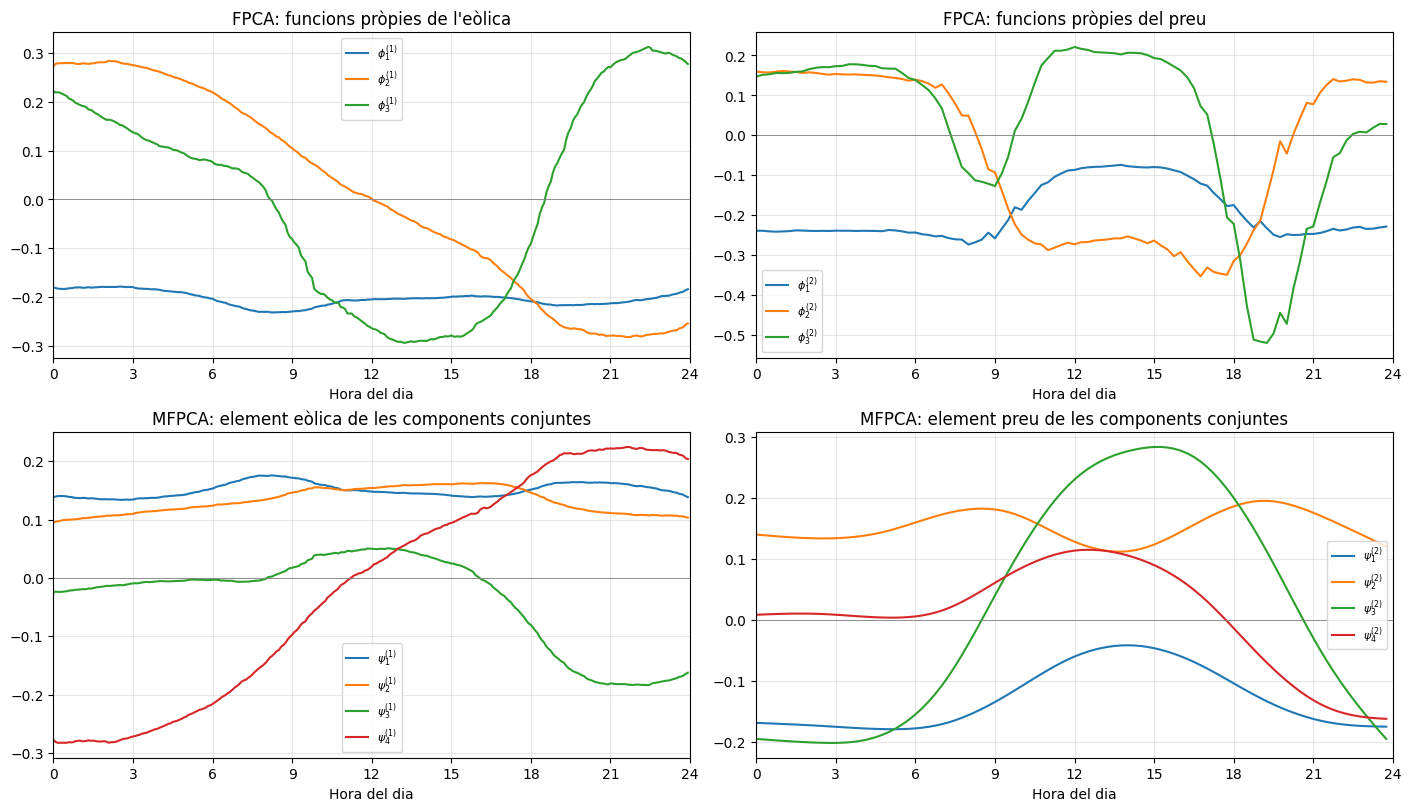

In [5]:
hores_e, hores_p = te, tp   # la malla ja està en hores
fig, axs = plt.subplots(2, 2, figsize=(14, 8), constrained_layout=True)

for k, f in enumerate(ufpca_e.eigenfunctions.values):
    axs[0, 0].plot(hores_e, f, label=f"$\\phi^{{(1)}}_{k+1}$")
for k, f in enumerate(ufpca_p.eigenfunctions.values):
    axs[0, 1].plot(hores_p, f, label=f"$\\phi^{{(2)}}_{k+1}$")
axs[0, 0].set_title("FPCA: funcions pròpies de l'eòlica")
axs[0, 1].set_title("FPCA: funcions pròpies del preu")

psi_e = mfpca.eigenfunctions.data[0].to_grid().values
psi_p = mfpca.eigenfunctions.data[1].to_grid().values
for m in range(len(mfpca.eigenvalues)):
    axs[1, 0].plot(hores_e, psi_e[m], label=f"$\\psi^{{(1)}}_{m+1}$")
    axs[1, 1].plot(hores_p, psi_p[m], label=f"$\\psi^{{(2)}}_{m+1}$")
axs[1, 0].set_title("MFPCA: element eòlica de les components conjuntes")
axs[1, 1].set_title("MFPCA: element preu de les components conjuntes")

for ax in axs.flat:
    ax.axhline(0, color="grey", lw=0.6)
    ax.set_xlim(0, 24); ax.set_xticks(range(0, 25, 3))
    ax.set_xlabel("Hora del dia"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.show()


Una diferència clau: a la FPCA cada component descriu **una sola** variable, mentre
que a la MFPCA cada component descriu les dues alhora. Per exemple, si una component
conjunta té l'element d'eòlica positiu i el de preu negatiu, captura el fet que els dies
de més vent tendeixen a tenir preus més baixos.

Es veu a la primera component conjunta: $\psi^{(1)}_1$ és positiva tot el dia i $\psi^{(2)}_1$ és negativa,
sobretot fora de les hores solars. Els dies amb un score $\rho_{i1}$ alt tenen més vent i preus més
baixos que la mitjana.


---
# Part 4 — Model VAR sobre els scores

Si $\mathbf{s}_i$ són els scores del dia $i$ (FPCA o MFPCA), el model VAR($p$) amb
variables exògenes és:

$$
\mathbf{s}_{i} = \mathbf{c} + A_1 \mathbf{s}_{i-1} + \dots + A_p \mathbf{s}_{i-p}
+ B\, \mathbf{d}_{i} + \boldsymbol{\varepsilon}_i
$$

- $A_1, \dots, A_p$ són matrius **completes**: el score de preu d'avui pot dependre del
  score d'eòlica d'ahir. Això recull la dependència creuada entre components de qualsevol
  índex, com vam veure a l'experiment de la permutació.
- $\mathbf{d}_i$ són variables indicadores del dia de la setmana (dilluns com a
  referència), perquè el preu és diferent els caps de setmana.
- L'ordre $p$ es tria amb el criteri BIC entre 1 i 7.

### Estacionarietat

El VAR suposa sèries estacionàries. Ho comprovem amb el test de Dickey-Fuller augmentat
(ADF) sobre cada score: un p-valor petit (< 0.05) indica estacionarietat.


In [6]:
dow = pd.get_dummies(dies.dayofweek).iloc[:, 1:].to_numpy(dtype=float)   # dilluns = referència

files = []
for nom, S in [("FPCA", S_fpca), ("MFPCA", S_mfpca)]:
    for k in range(S.shape[1]):
        files.append({"opció": nom, "score": k + 1, "p-valor ADF": round(adfuller(S[:, k])[1], 4)})
pd.DataFrame(files).pivot(index="score", columns="opció", values="p-valor ADF")


opció,FPCA,MFPCA
score,,
1,0.0000,0.6747
2,0.0000,0.7464
3,0.0109,0.3642
4,0.9342,0.0000
5,0.5739,NaN
6,0.0019,NaN


In [7]:
for nom, S in [("FPCA", S_fpca), ("MFPCA", S_mfpca)]:
    ordre = VAR(S, exog=dow).select_order(maxlags=MAX_LAGS)
    print(f"{nom}: ordre triat per BIC = {ordre.bic},  per AIC = {ordre.aic}")


FPCA: ordre triat per BIC = 1,  per AIC = 4
MFPCA: ordre triat per BIC = 1,  per AIC = 5


---
# Part 5 — Predicció i reconstrucció

Amb els scores predits $\hat{\mathbf{s}}_{n+1}$ es desfà la transformació en ordre invers:

1. **Reconstrucció** de la corba escalada:
   $\hat{z}^{(j)}_{n+1}(t) = \sum_k \hat{\xi}^{(j)}_{n+1,k}\,\phi^{(j)}_k(t)$ (FPCA) o
   $\hat{z}^{(j)}_{n+1}(t) = \sum_m \hat{\rho}_{n+1,m}\,\psi^{(j)}_m(t)$ (MFPCA).
2. **Desfer l'escalat i el centrat**:
   $\hat{x}^{(j)}_{n+1}(t) = \bar{x}^{(j)}(t) + s_j\, \hat{z}^{(j)}_{n+1}(t)$.

El resultat són els dos vectors de predicció: 288 valors d'eòlica i 96 de preu.

La funció següent fa tot el procés per a un dia $d$, fent servir **només** els dies
anteriors (de $0$ a $d-1$): centrat, escalat, reducció de dimensió, VAR i reconstrucció.


In [8]:
def ajust_var(S, ex, ex_seguent):
    # Ajusta el VAR (ordre per BIC) i prediu un pas endavant
    model = VAR(S, exog=ex)
    p = max(1, model.select_order(maxlags=MAX_LAGS).bic)
    res = model.fit(p)
    return res.forecast(S[-p:], steps=1, exog_future=ex_seguent[None, :])[0], p


def prediu(d, opcio):
    # Prediu les corbes del dia d amb els dies 0..d-1. Retorna (eòlica, preu, info)
    mus, ss, fds = [], [], []
    for X, t in [(Xe[:d], te), (Xp[:d], tp)]:
        mu, s = escala(X, t)
        mus.append(mu); ss.append(s); fds.append(fdata((X - mu) / s, t))

    if opcio == "FPCA":
        models = [UFPCA(n_components=VAR_EXPLICADA, method="covariance") for _ in fds]
        S_parts = []
        for u, fd in zip(models, fds):
            u.fit(fd); S_parts.append(u.transform(fd))
        dims = [S.shape[1] for S in S_parts]
        s_pred, p = ajust_var(np.hstack(S_parts), dow[:d], dow[d])
        talls = np.cumsum([0] + dims)
        z_pred = [models[j].inverse_transform(s_pred[None, talls[j]:talls[j + 1]]).values[0]
                  for j in range(2)]
    else:
        md_ = MultivariateFunctionalData(fds)
        m = MFPCA(n_components=VAR_EXPLICADA, method="covariance",
                  univariate_expansions=[{"method": "UFPCA", "n_components": 10}] * 2)
        m.fit(md_)
        S = m.transform(md_)
        dims = [S.shape[1]]
        s_pred, p = ajust_var(S, dow[:d], dow[d])
        rec = m.inverse_transform(s_pred[None, :])
        z_pred = [rec.data[j].values[0] for j in range(2)]

    x_pred = [mus[j] + ss[j] * z_pred[j] for j in range(2)]
    return x_pred[0], x_pred[1], {"dims": dims, "p": p}


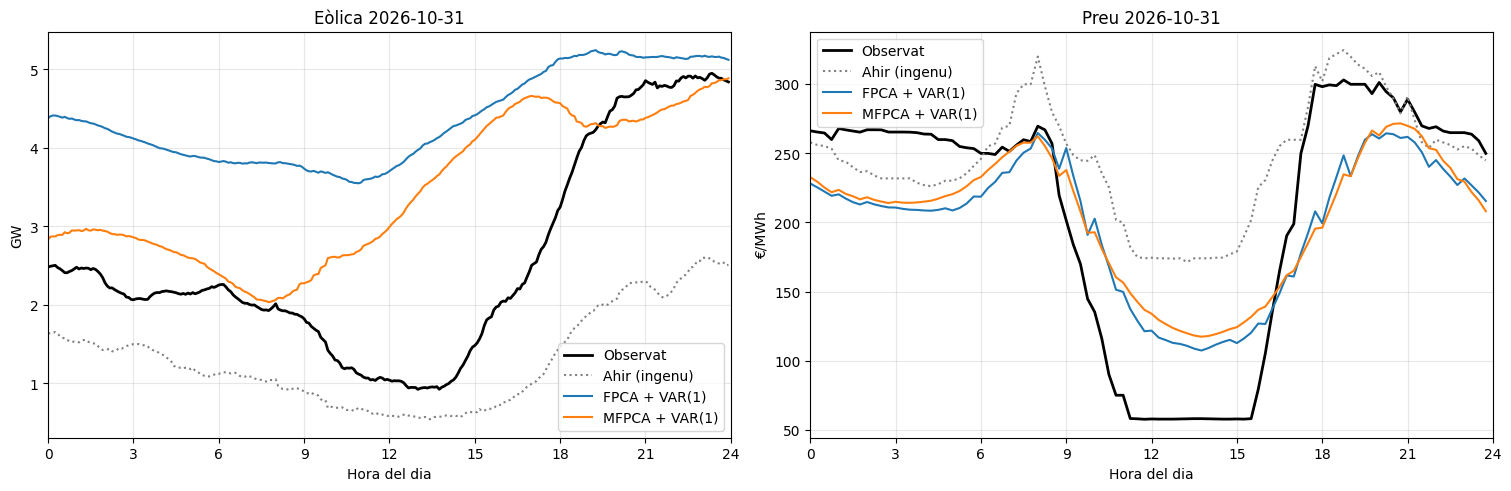

In [9]:
d = n - 1   # exemple: l'últim dia disponible
pred = {op: prediu(d, op) for op in ["FPCA", "MFPCA"]}

fig, axs = plt.subplots(1, 2, figsize=(15, 4.8), constrained_layout=True)
axs[0].plot(hores_e, Xe[d], color="black", lw=2, label="Observat")
axs[1].plot(hores_p, Xp[d], color="black", lw=2, label="Observat")
axs[0].plot(hores_e, Xe[d - 1], color="grey", ls=":", label="Ahir (ingenu)")
axs[1].plot(hores_p, Xp[d - 1], color="grey", ls=":", label="Ahir (ingenu)")
for op, color in [("FPCA", "tab:blue"), ("MFPCA", "tab:orange")]:
    e, p_, info = pred[op]
    axs[0].plot(hores_e, e, color=color, label=f"{op} + VAR({info['p']})")
    axs[1].plot(hores_p, p_, color=color, label=f"{op} + VAR({info['p']})")
axs[0].set_title(f"Eòlica {dies[d].date()}"); axs[0].set_ylabel("GW")
axs[1].set_title(f"Preu {dies[d].date()}"); axs[1].set_ylabel("€/MWh")
for ax in axs:
    ax.set_xlim(0, 24); ax.set_xticks(range(0, 25, 3)); ax.set_xlabel("Hora del dia")
    ax.grid(alpha=0.3); ax.legend()
plt.show()


---
# Part 6 — Avaluació rodant

Per a cadascun dels últims 60 dies $d$: s'ajusta tota la pipeline amb els dies
anteriors i es prediu el dia $d$. Es compara amb tres predictors de referència:

| Referència | Predicció del dia $d$ |
|---|---|
| Ingenu (ahir) | la corba del dia $d-1$ |
| Ingenu setmanal | la corba del dia $d-7$ |
| Mitjana | la corba mitjana de tots els dies anteriors |

Mètriques per dia i variable, sobre tots els punts del dia:

$$
\text{RMSE}_d = \sqrt{\frac{1}{T}\sum_{t}\big(\hat{x}_d(t) - x_d(t)\big)^2},
\qquad
\text{MAE}_d = \frac{1}{T}\sum_{t}\big|\hat{x}_d(t) - x_d(t)\big|
$$

*(Aquesta cel·la tarda uns minuts: ajusta 120 vegades la pipeline.)*


In [10]:
files = []
for d in range(n - N_TEST, n):
    obs = [Xe[d], Xp[d]]
    e_f, p_f, _ = prediu(d, "FPCA")
    e_m, p_m, _ = prediu(d, "MFPCA")
    candidats = {
        "FPCA + VAR": [e_f, p_f],
        "MFPCA + VAR": [e_m, p_m],
        "Ingenu (ahir)": [Xe[d - 1], Xp[d - 1]],
        "Ingenu setmanal": [Xe[d - 7], Xp[d - 7]],
        "Mitjana": [Xe[:d].mean(0), Xp[:d].mean(0)],
    }
    for metode, pr in candidats.items():
        for j, var_ in enumerate(["Eòlica (GW)", "Preu (€/MWh)"]):
            err = pr[j] - obs[j]
            files.append({"dia": dies[d], "mètode": metode, "variable": var_,
                          "RMSE": float(np.sqrt(np.mean(err ** 2))), "MAE": float(np.mean(np.abs(err)))})

res = pd.DataFrame(files)
taula = res.groupby(["variable", "mètode"])[["RMSE", "MAE"]].mean()
ref = taula.xs("Ingenu (ahir)", level="mètode")["RMSE"]
taula["millora RMSE vs ahir"] = [f"{100 * (1 - v / ref[var_]):.1f} %" for (var_, _), v in taula["RMSE"].items()]
taula.round(2)


RMSE    MAE millora RMSE vs ahir
variable     mètode                                            
Eòlica (GW)  FPCA + VAR        2.11   1.79               29.8 %
             Ingenu (ahir)     3.00   2.58                0.0 %
             Ingenu setmanal   3.77   3.34              -25.5 %
             MFPCA + VAR       2.05   1.73               31.8 %
             Mitjana           3.18   2.96               -5.9 %
Preu (€/MWh) FPCA + VAR       34.86  27.53               19.2 %
             Ingenu (ahir)    43.15  34.15                0.0 %
             Ingenu setmanal  55.32  43.86              -28.2 %
             MFPCA + VAR      39.53  31.35                8.4 %
             Mitjana          97.20  89.22             -125.3 %

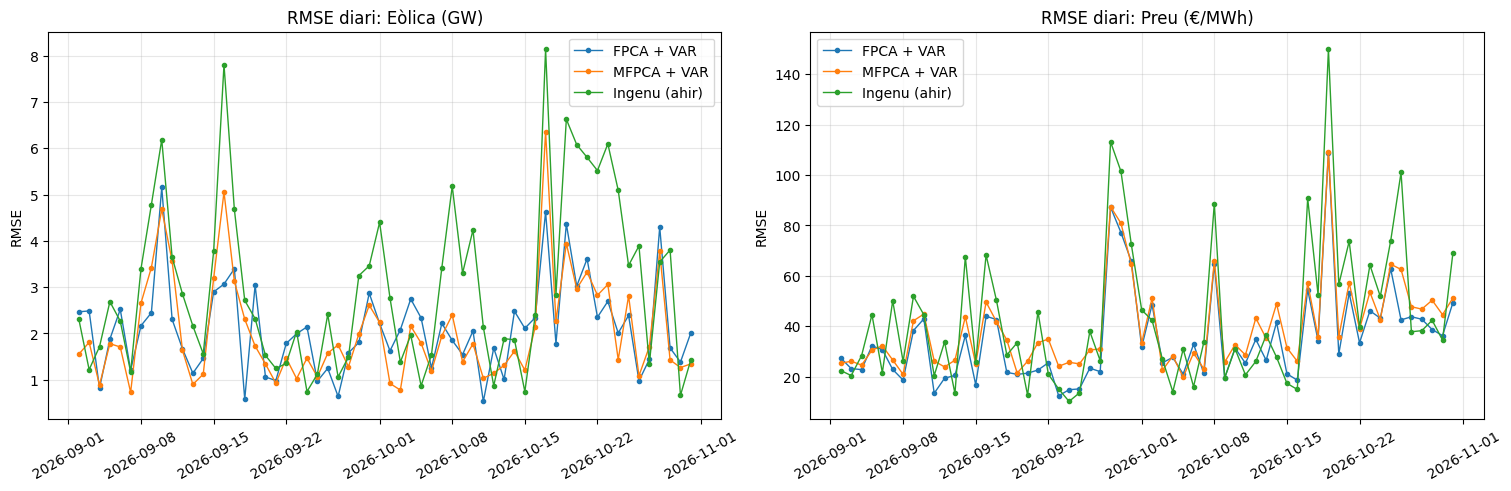

In [11]:
fig, axs = plt.subplots(1, 2, figsize=(15, 4.8), constrained_layout=True)
for ax, var_ in zip(axs, ["Eòlica (GW)", "Preu (€/MWh)"]):
    sub = res[res["variable"] == var_]
    for metode in ["FPCA + VAR", "MFPCA + VAR", "Ingenu (ahir)"]:
        s = sub[sub["mètode"] == metode]
        ax.plot(s["dia"], s["RMSE"], marker="o", ms=3, lw=1, label=metode)
    ax.set_title(f"RMSE diari: {var_}")
    ax.set_ylabel("RMSE"); ax.grid(alpha=0.3); ax.legend()
    ax.tick_params(axis="x", rotation=30)
plt.show()


---
# Conclusió

- **La pipeline funciona de principi a fi**: de les dades d'ESIOS a una predicció de les
  corbes del dia següent (288 valors d'eòlica i 96 de preu), passant per la reducció a uns
  pocs scores i un VAR.
- **Totes dues opcions milloren les referències ingènues** en les dues variables: respecte
  a repetir la corba d'ahir, l'RMSE baixa un 30–32 % a l'eòlica i un 8–19 % al preu. La predicció "repetir la mitjana" és especialment dolenta per
  al preu, perquè el nivell del preu canvia molt al llarg de l'any.
- **FPCA vs MFPCA**: en aquest període la MFPCA és lleugerament millor per a l'eòlica
  (RMSE 2.05 vs 2.11 GW) i la FPCA per separat és clarament millor per al preu
  (34.9 vs 39.5 €/MWh). La MFPCA fa servir menys dimensions, però obliga
  totes dues variables a compartir les mateixes components, cosa que pot perjudicar la
  que té una estructura pròpia més rica (el preu).
- **Limitacions i millores possibles**:
  - L'eòlica depèn del temps meteorològic. Predir-la només a partir dels dies anteriors
    té un límit clar; afegir la previsió eòlica de REE (indicador 541) com a variable
    exògena hauria de millorar-la molt.
  - Segons el test ADF (Part 4), alguns scores no són estacionaris: els dos primers scores
    del preu a la FPCA i els tres primers de la MFPCA, que barregen el nivell del preu. És
    coherent amb la pujada del preu dels últims mesos, i pot explicar per què la MFPCA
    prediu pitjor el preu. Es podria diferenciar els scores o fer servir una finestra
    mòbil d'entrenament.
  - 60 dies de prova són pocs per afirmar que una opció és millor que l'altra: caldria un
    test de comparació de prediccions (p. ex. Diebold-Mariano) o un període de prova més llarg.
